# Initial Set Up



In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

# --- Configuration ---

We assgin variables for future use as follows
- `DATASET_PATH` is used to reference the file directory where the pictures are located.
- `IMAGE_SIZE` is used to rescale images to make them compatible with our processes.
- `NUM_EIGENFACES` is used to determine how many singular values to create

In [4]:
DATASET_PATH = "./att_faces"
TESTING_PATH = "./testing_images"
IMAGE_SIZE = (112, 92)
NUM_EIGENFACES = 400

# --- Load Images ---

We define a function to load the images from the AT&T image database into an array of vectors, where each vector is an image of a person, and a list of labels naming the person.

We convert an image, represented as a matrix of pixels $x_{n,m}$ in row $n$ and column $m$ to a vector with dimension $1 \times nm$ as follows

$$\text{flatten}\left(\begin{bmatrix} 
x_{1,1} & x_{1,2} & \dots & x_{1,112} \\
x_{2,1} & x_{2,2} & \dots & x_{2,112}\\
\vdots & \vdots & \ddots & \vdots \\
x_{92,1} & x_{92,2} & \dots & x_{92,112}
\end{bmatrix}\right) = \begin{bmatrix}
x_{1,1} & \dots & x_{1,112} & x_{2,1} & \dots & x_{92,122}
\end{bmatrix}
$$



In [5]:
def load_images(dataset_path):
    images = []
    labels = []
    for person_dir in os.listdir(dataset_path):
        person_path = os.path.join(dataset_path, person_dir) #./att_faces/s_1
        if os.path.isdir(person_path):
            for filename in os.listdir(person_path): #grabs all images in folder
                img_path = os.path.join(person_path, filename)
                img = Image.open(img_path).convert('L')  # Convert to grayscale
                img = img.resize(IMAGE_SIZE)
                images.append(np.asarray(img, dtype=np.float32).flatten())
                labels.append(person_dir)
    return np.array(images), labels

# --- Compute PCA ---

We define a function which takes our set of images and a number to return that number of eigenfaces.

In [6]:
def compute_eigenfaces(images, num_components):
    scaler = StandardScaler(with_std=False)    #subtracts face with the average face, does not scale to average
    images_centered = scaler.fit_transform(images)    #makes the scaler compatible with the shape of the vectors in the array
    pca = PCA(n_components=num_components,    #intizilizes PCA 
              svd_solver='randomized',
              whiten=True)
    pca.fit(images_centered)    #performs pca on the centered images
    return pca, scaler.mean_

# --- Visualize Eigenfaces ---



In [7]:
def plot_eigenfaces(pca, image_shape, num_faces=10):
    fig, axes = plt.subplots(1, num_faces, figsize=(15, 5))
    for i in range(num_faces):
        axes[i].imshow(pca.components_[i].reshape(image_shape[1], image_shape[0]), cmap='gray')
        axes[i].axis('off')
        axes[i].set_title(f"PC {i+1}")
    plt.suptitle("Top Eigenfaces")
    plt.show()

In [8]:
# --- Plot all faces ---
def plot_faces(images, image_shape, num_faces):
    fig, axes = plt.subplots(40, 10, figsize=(10, 40))
    n=0
    for i in range(40):
        for j in range(10):
            axes[i,j].imshow(images[n].reshape(image_shape[1], image_shape[0]), cmap='gray')
            axes[i,j].axis('off')
            n += 1
    plt.show()

Loading images...


Loaded 400 images.


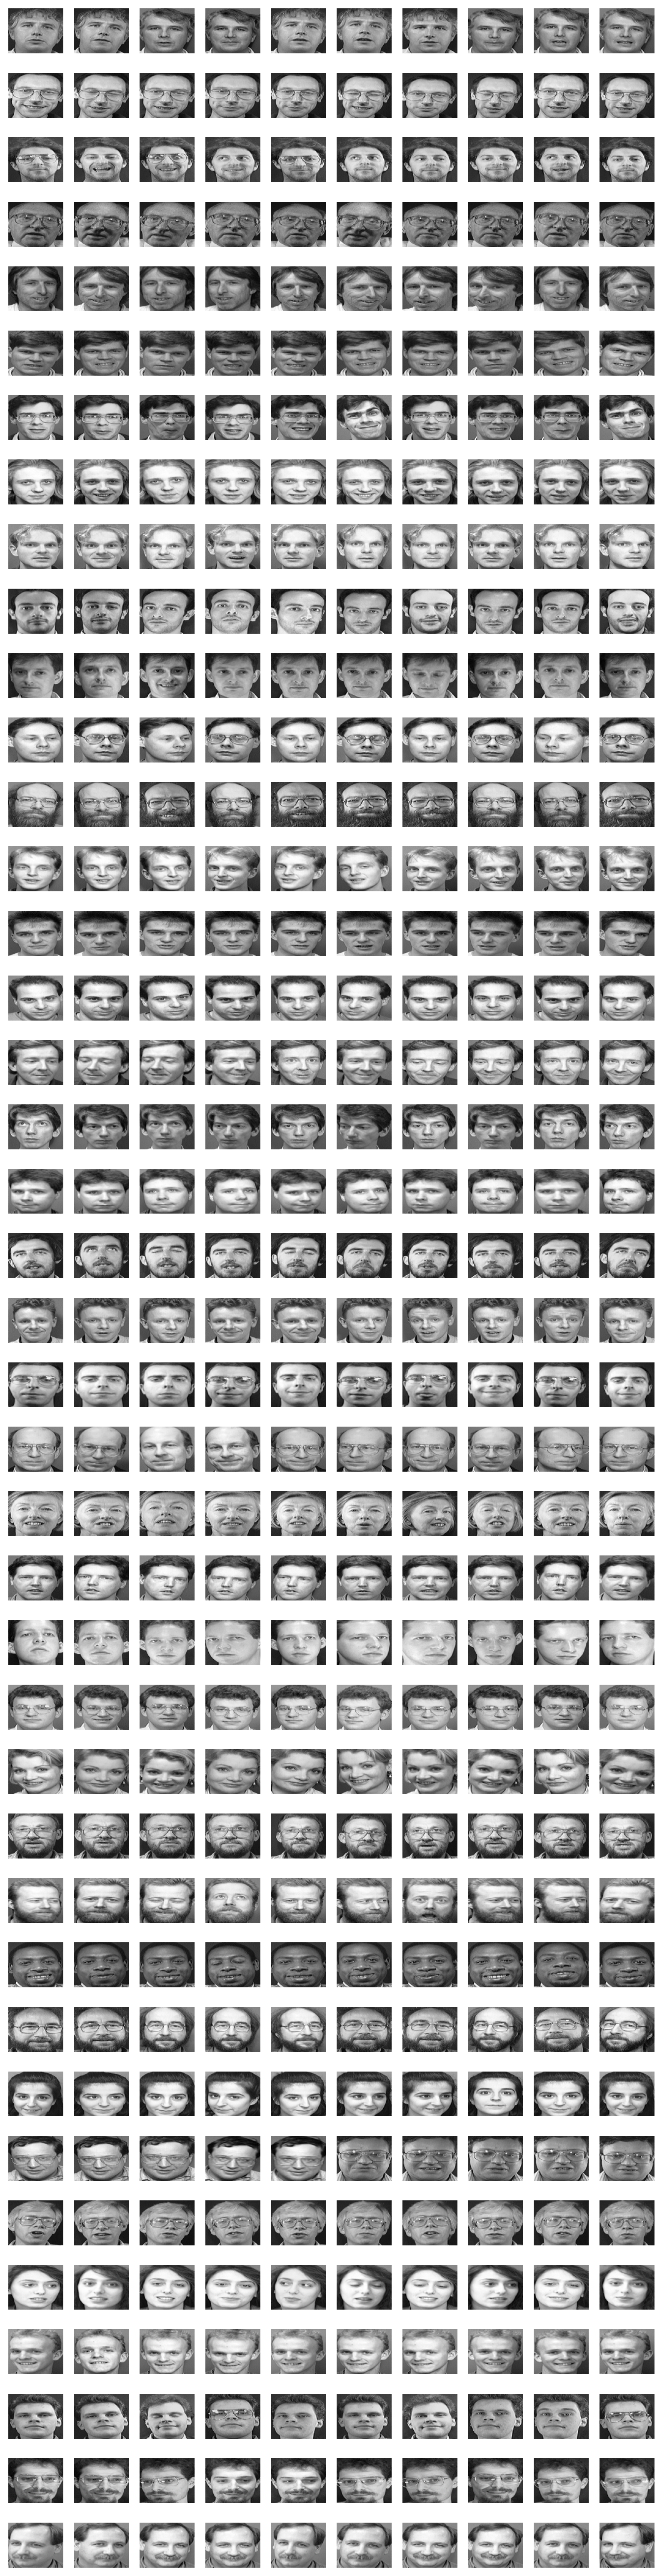

Computing PCA...


Visualizing eigenfaces...


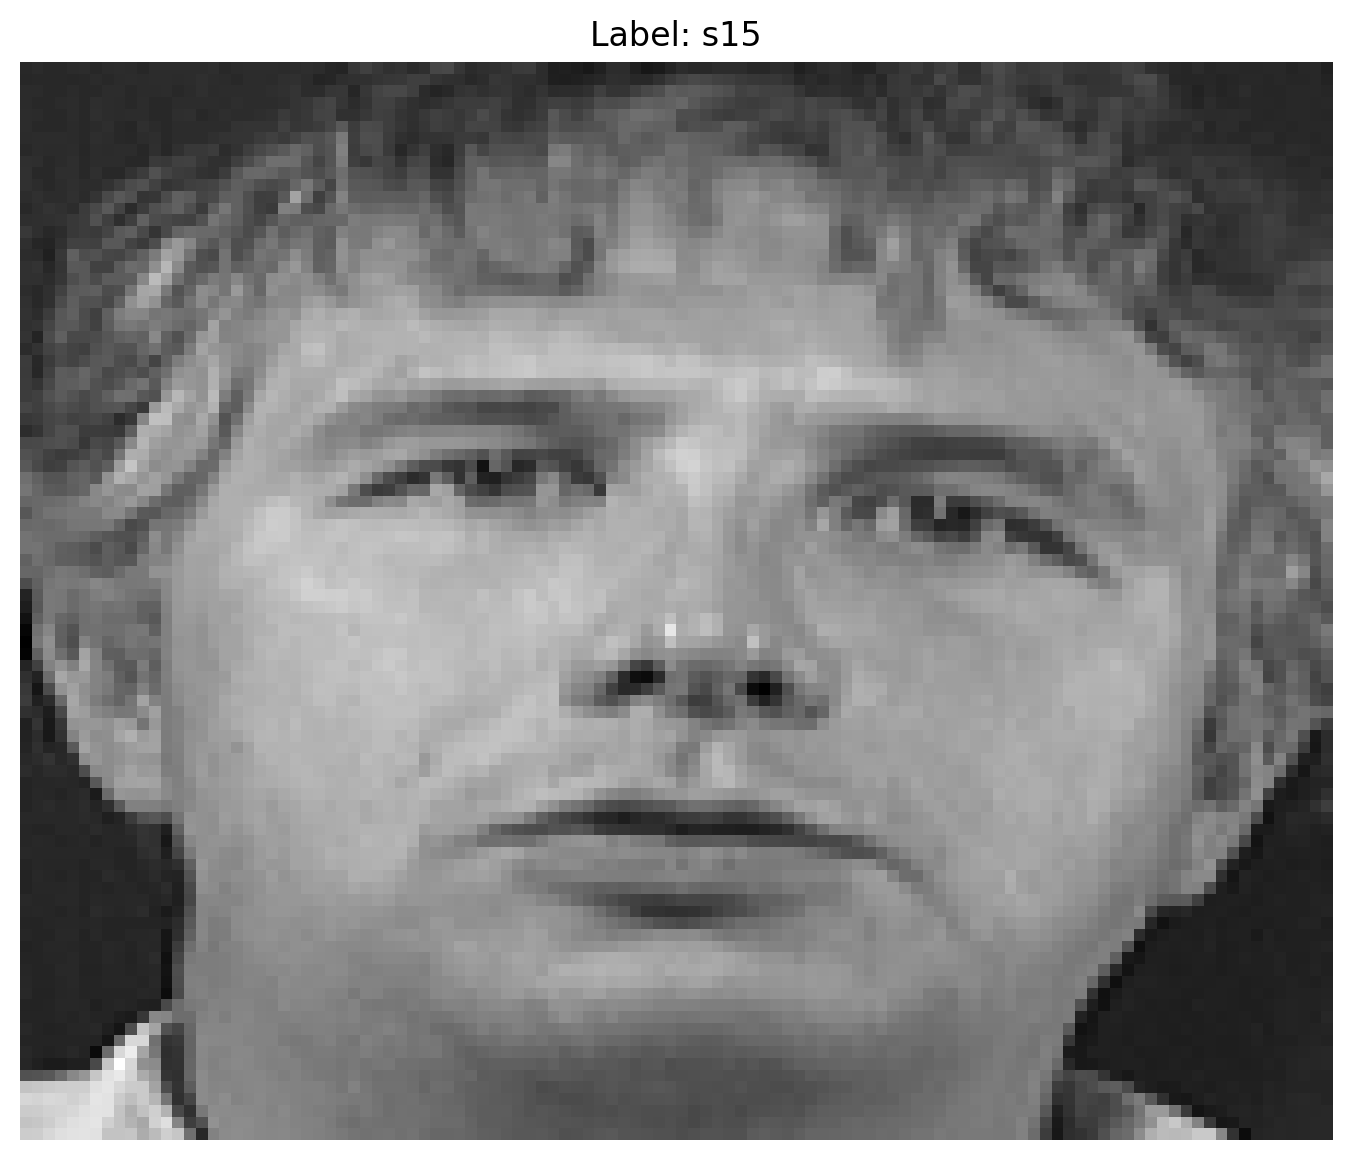

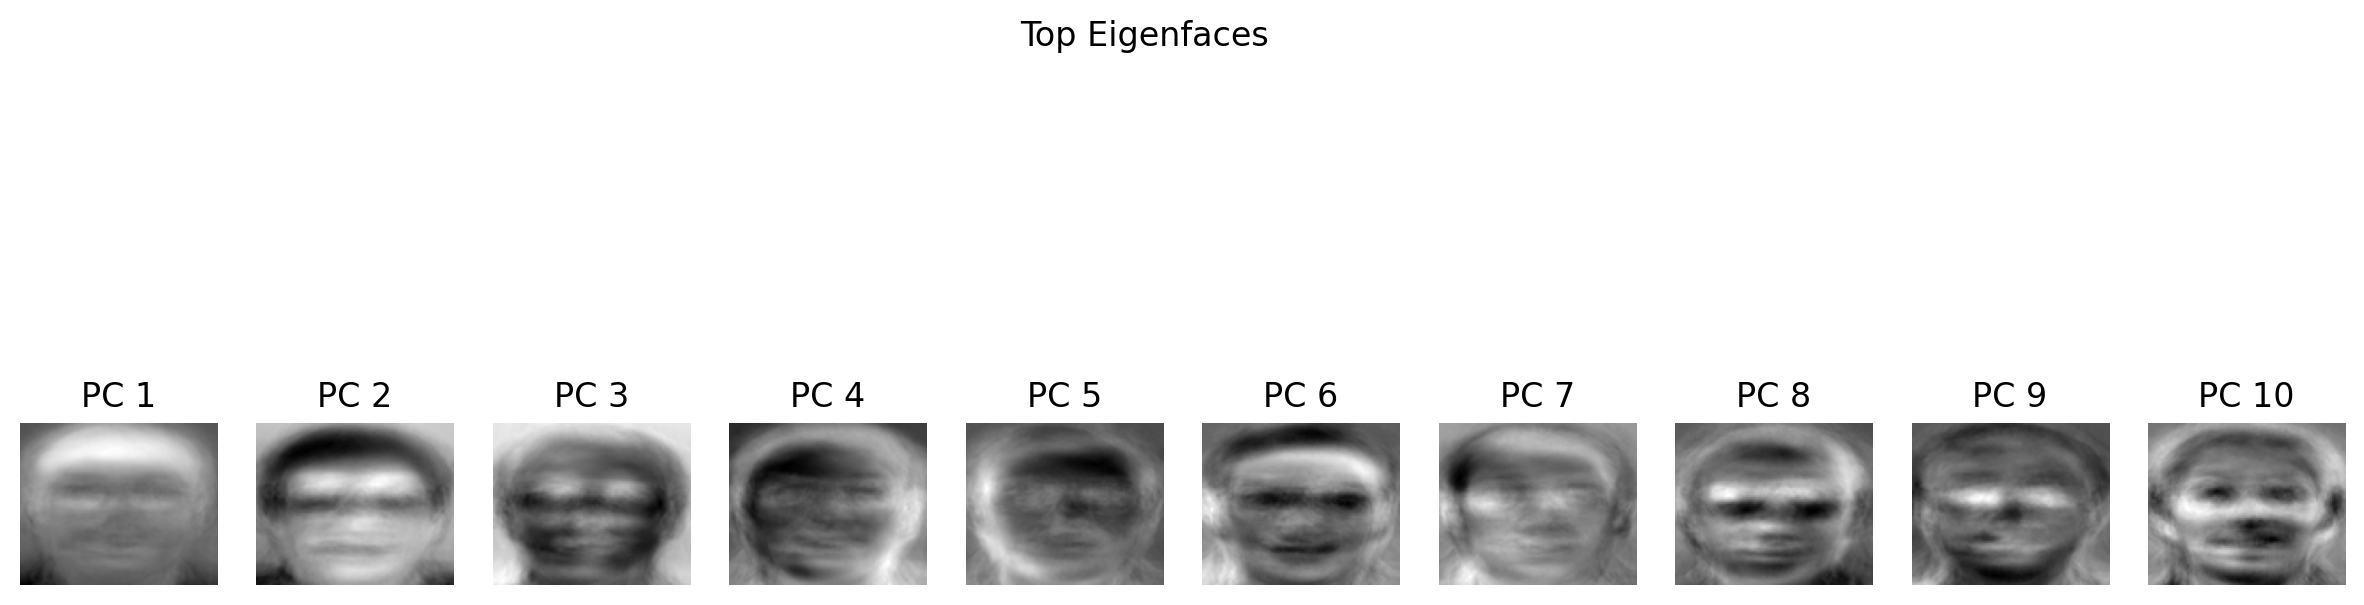

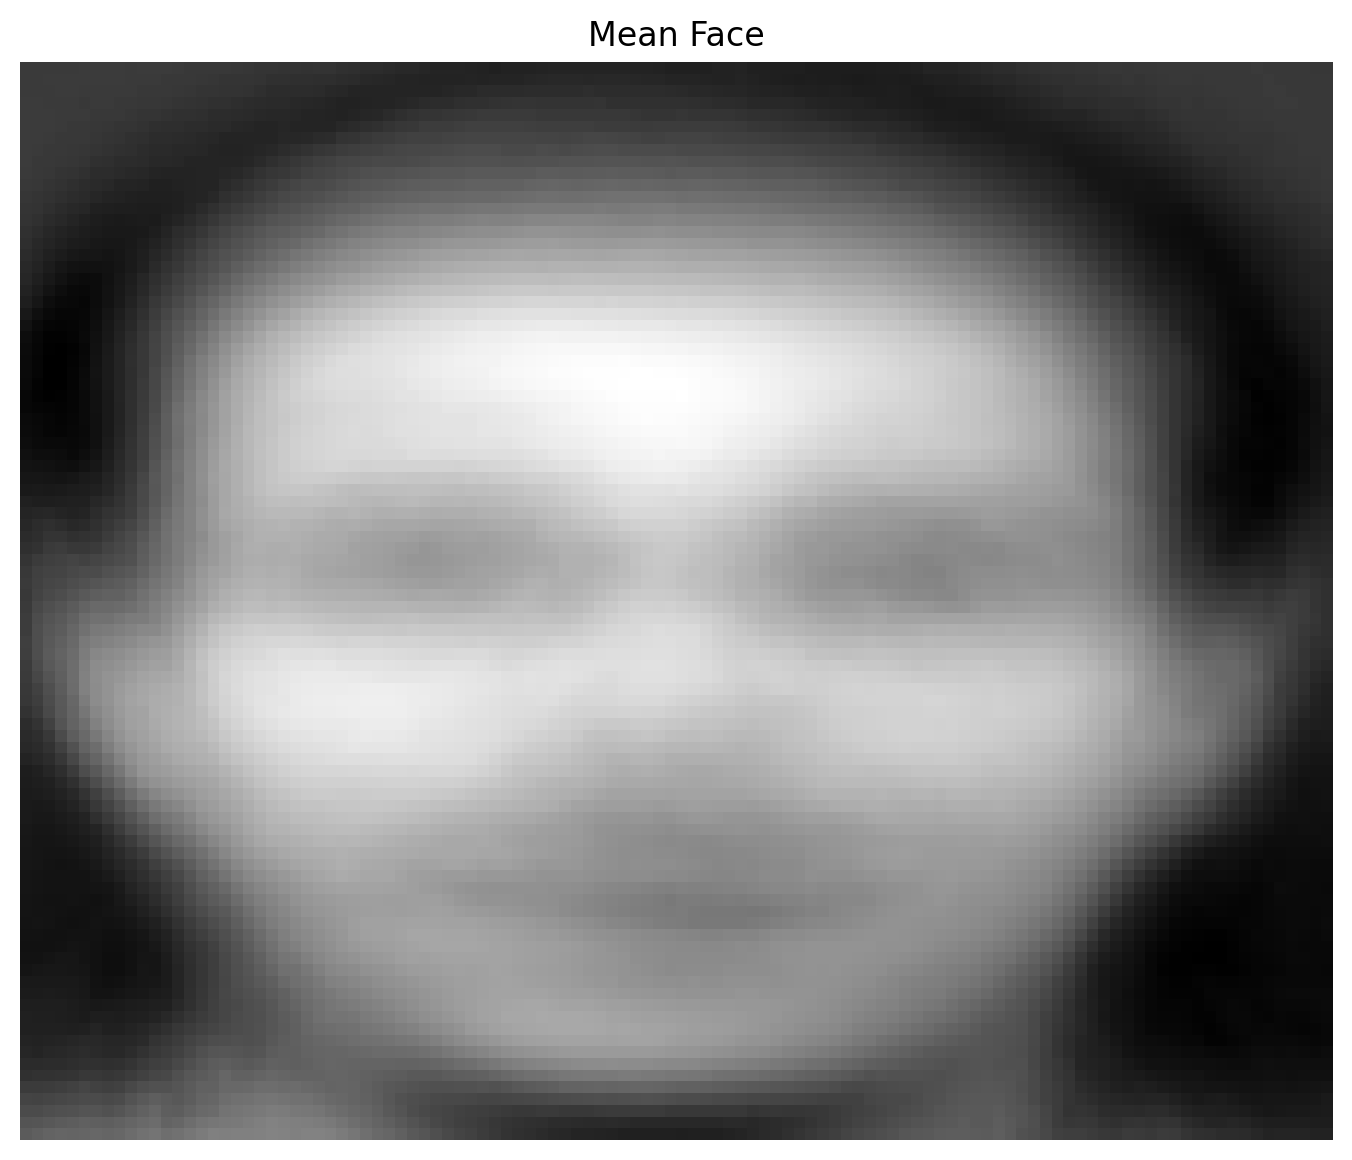

In [9]:
# --- Main Execution ---
if __name__ == "__main__":
    print("Loading images...")
    images, labels = load_images(DATASET_PATH)
    test_images, test_labels = load_images(TESTING_PATH)
    print(f"Loaded {len(images)} images.")

    # Plot each person
    plot_faces(images, IMAGE_SIZE, len(images))
    
    # Reshape and plot the first image
    
    first_image = images[0].reshape(IMAGE_SIZE[1], IMAGE_SIZE[0])  # height x width
    plt.imshow(first_image, cmap='gray')
    plt.title(f"Label: {labels[0]}")
    plt.axis('off')

    print("Computing PCA...")
    pca, mean_face = compute_eigenfaces(images, NUM_EIGENFACES)

    print("Visualizing eigenfaces...")
    plot_eigenfaces(pca, IMAGE_SIZE, num_faces=10)

    # Optional: Visualize mean face
    plt.imshow(mean_face.reshape(IMAGE_SIZE[1], IMAGE_SIZE[0]), cmap='gray')
    plt.title("Mean Face")
    plt.axis('off')
    plt.show()

# Image Reconstruction



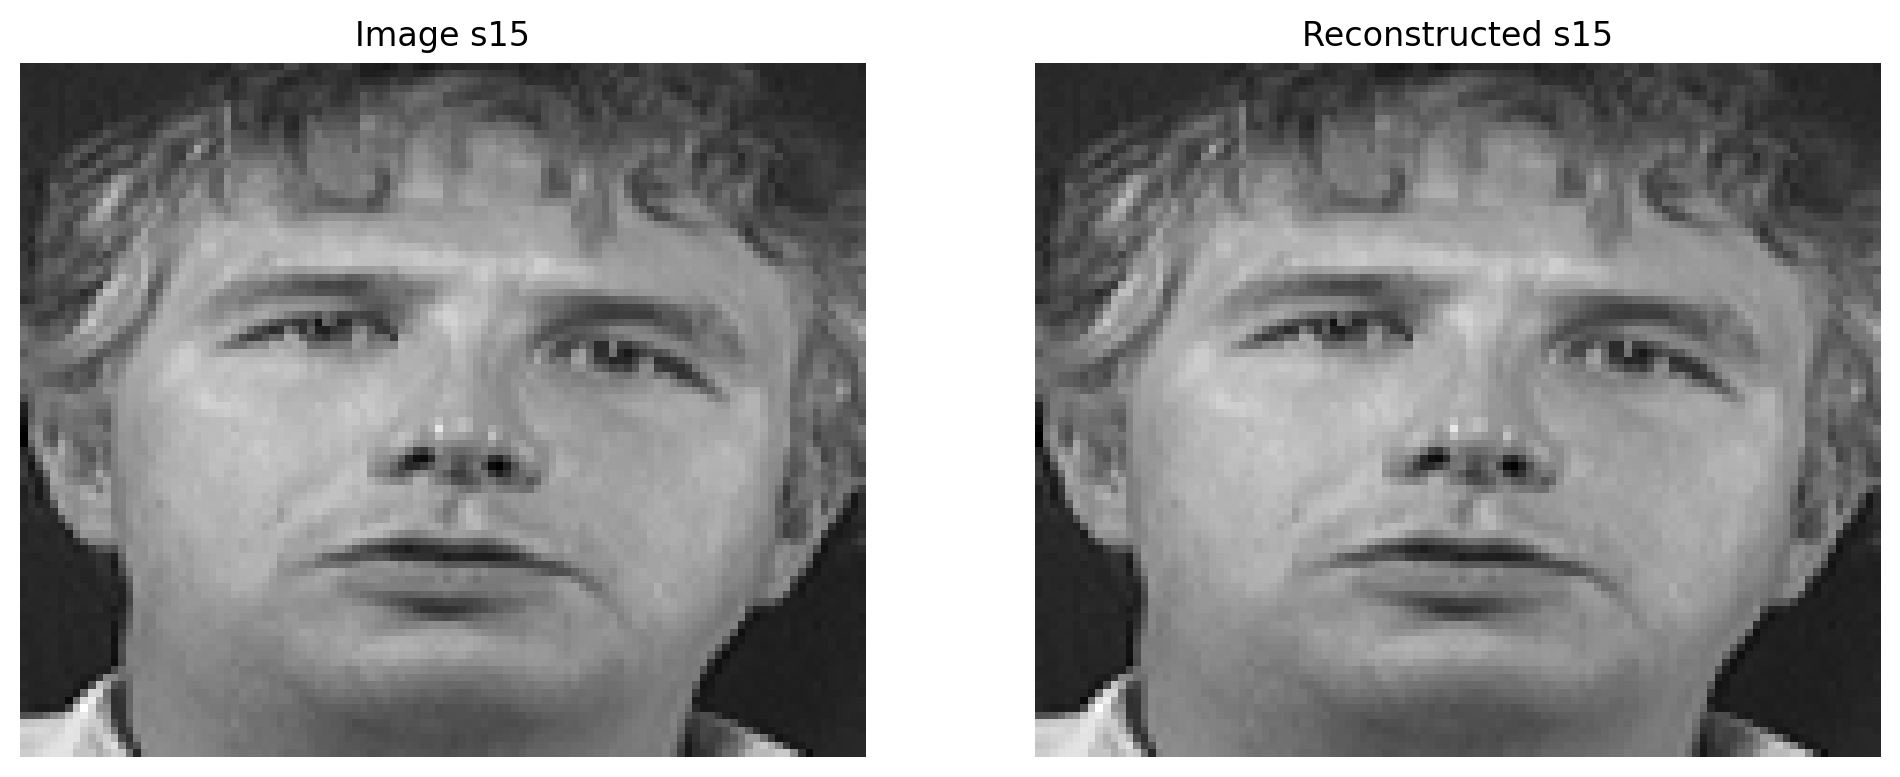

In [10]:
fig, axes = plt.subplots(1, 2)
img_num = 0



UTUx = pca.components_.T@(pca.components_@(images[img_num]-mean_face))+mean_face

axes[0].imshow(images[img_num].reshape(IMAGE_SIZE[1], IMAGE_SIZE[0]), cmap='gray')
axes[1].imshow((UTUx).reshape(IMAGE_SIZE[1], IMAGE_SIZE[0]), cmap='gray')

axes[0].set_title(f"Image {labels[img_num]}")
axes[1].set_title(f"Reconstructed {labels[img_num]}")


for i in range(2):
    axes[i].axis('off')

plt.show()

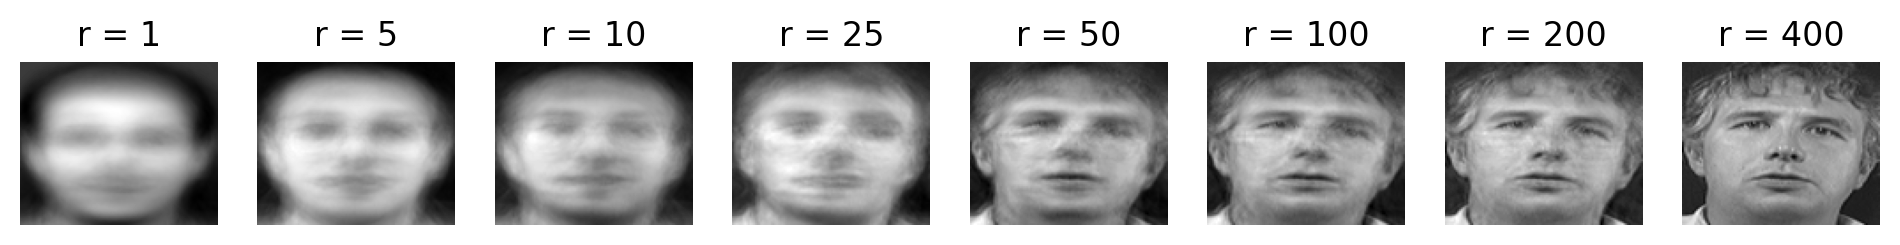

In [11]:
# --- Reconstruction ---
fig, axes = plt.subplots(1, 8)
img_num = 0
i = 0
for r in [1, 5, 10, 25, 50, 100, 200, 400]:
    x = images[0]
    UTUx = pca.components_[0:r].T@(pca.components_[0:r]@(x - mean_face))+mean_face
    axes[i].imshow(UTUx.reshape(IMAGE_SIZE[1], IMAGE_SIZE[0]), cmap='gray')
    axes[i].set_title(f"r = {r}")
    axes[i].axis('off')
    i += 1
plt.show()

# Image Classification



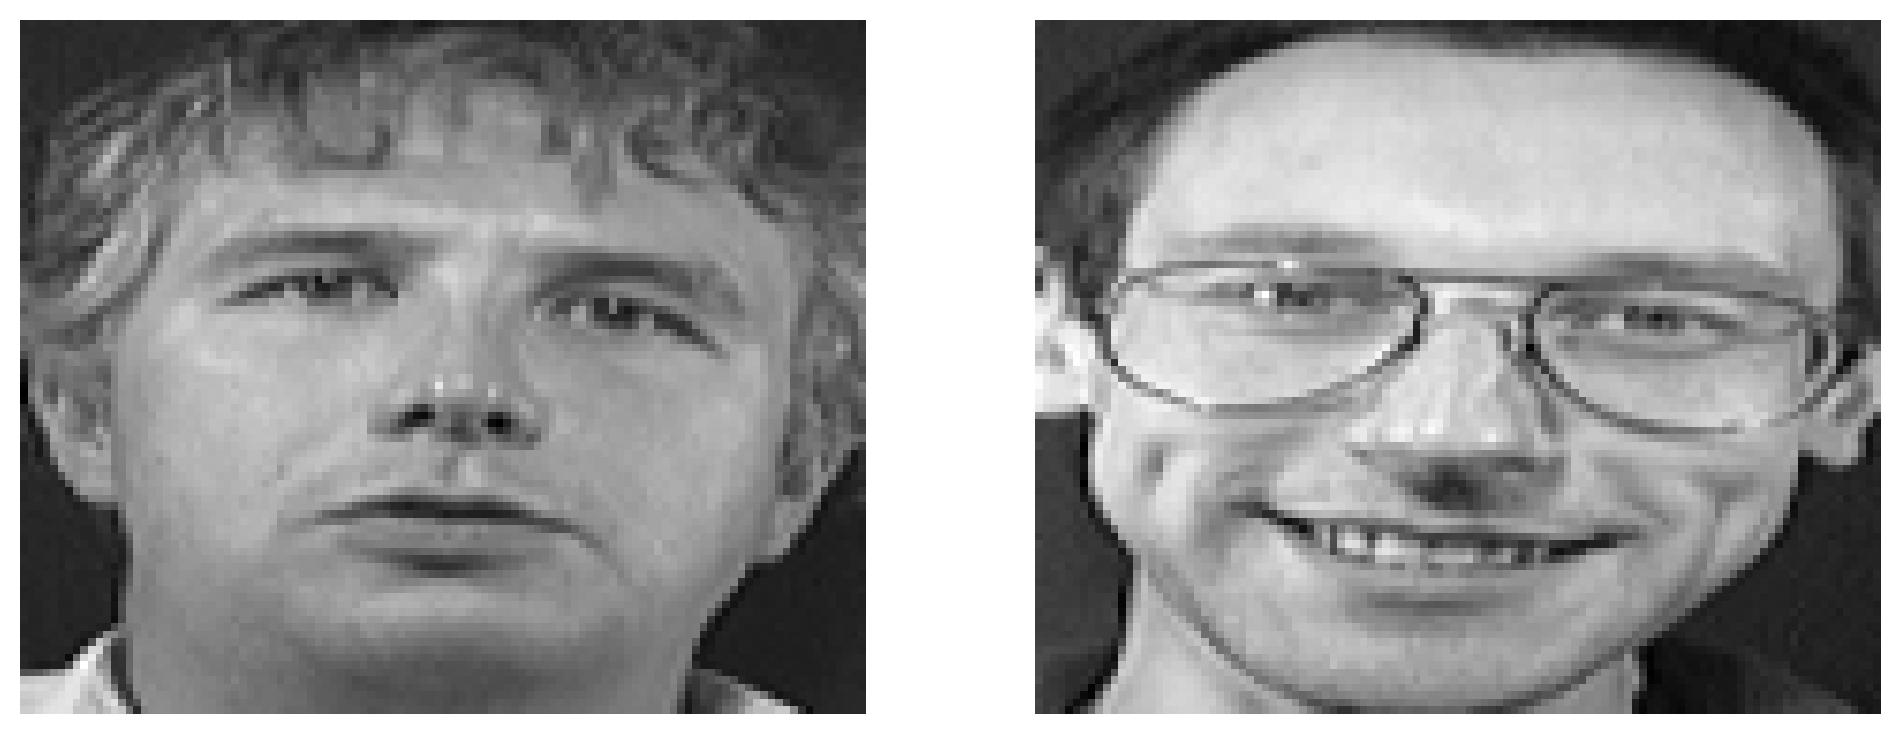

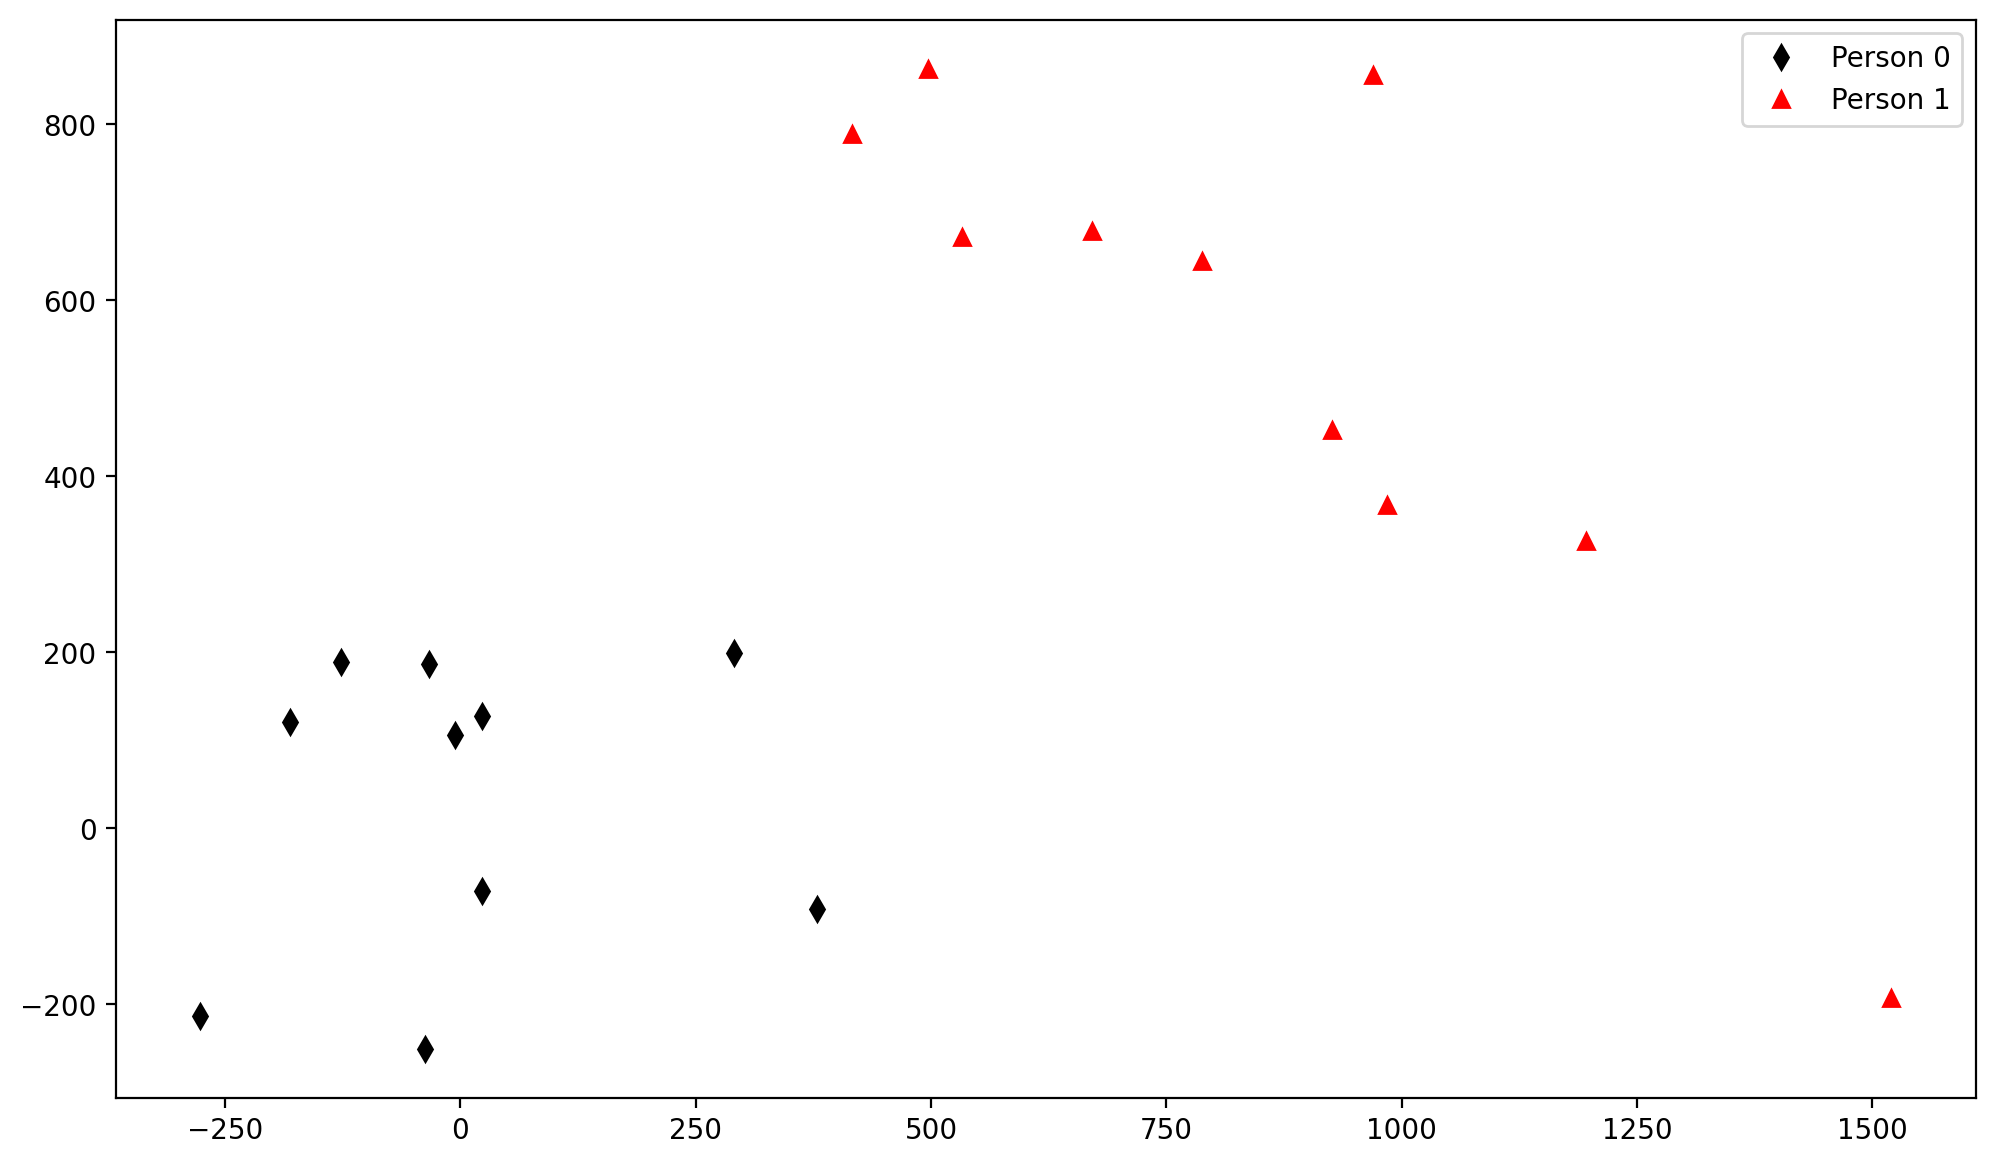

In [12]:
Person1 = 0
Person2 = 1

P1 = images[Person1*10:Person1*10+10] #grab all 10 images of person 1 and 2
P2 = images[Person2*10:Person2*10+10]

P1 = P1 - np.tile(mean_face,(10,1))
P2 = P2 - np.tile(mean_face,(10,1))

PCAmodes = [6,7]
PCACoordsP1 = pca.components_.T[:,PCAmodes - np.ones_like(PCAmodes)].T@P1.T
PCACoordsP2 = pca.components_.T[:,PCAmodes - np.ones_like(PCAmodes)].T@P2.T

fig, axes = plt.subplots(1, 2)

axes[0].imshow(images[Person1*10].reshape(IMAGE_SIZE[1], IMAGE_SIZE[0]), cmap='gray'), axes[0].axis('off')
axes[1].imshow(images[Person2*10].reshape(IMAGE_SIZE[1], IMAGE_SIZE[0]), cmap='gray'), axes[1].axis('off')
plt.show()

plt.plot(PCACoordsP1[0,:],PCACoordsP1[1,:],'d',color='k',label=f'Person {Person1}')
plt.plot(PCACoordsP2[0,:],PCACoordsP2[1,:],'^',color='r',label=f'Person {Person2}')

plt.legend()
plt.show()

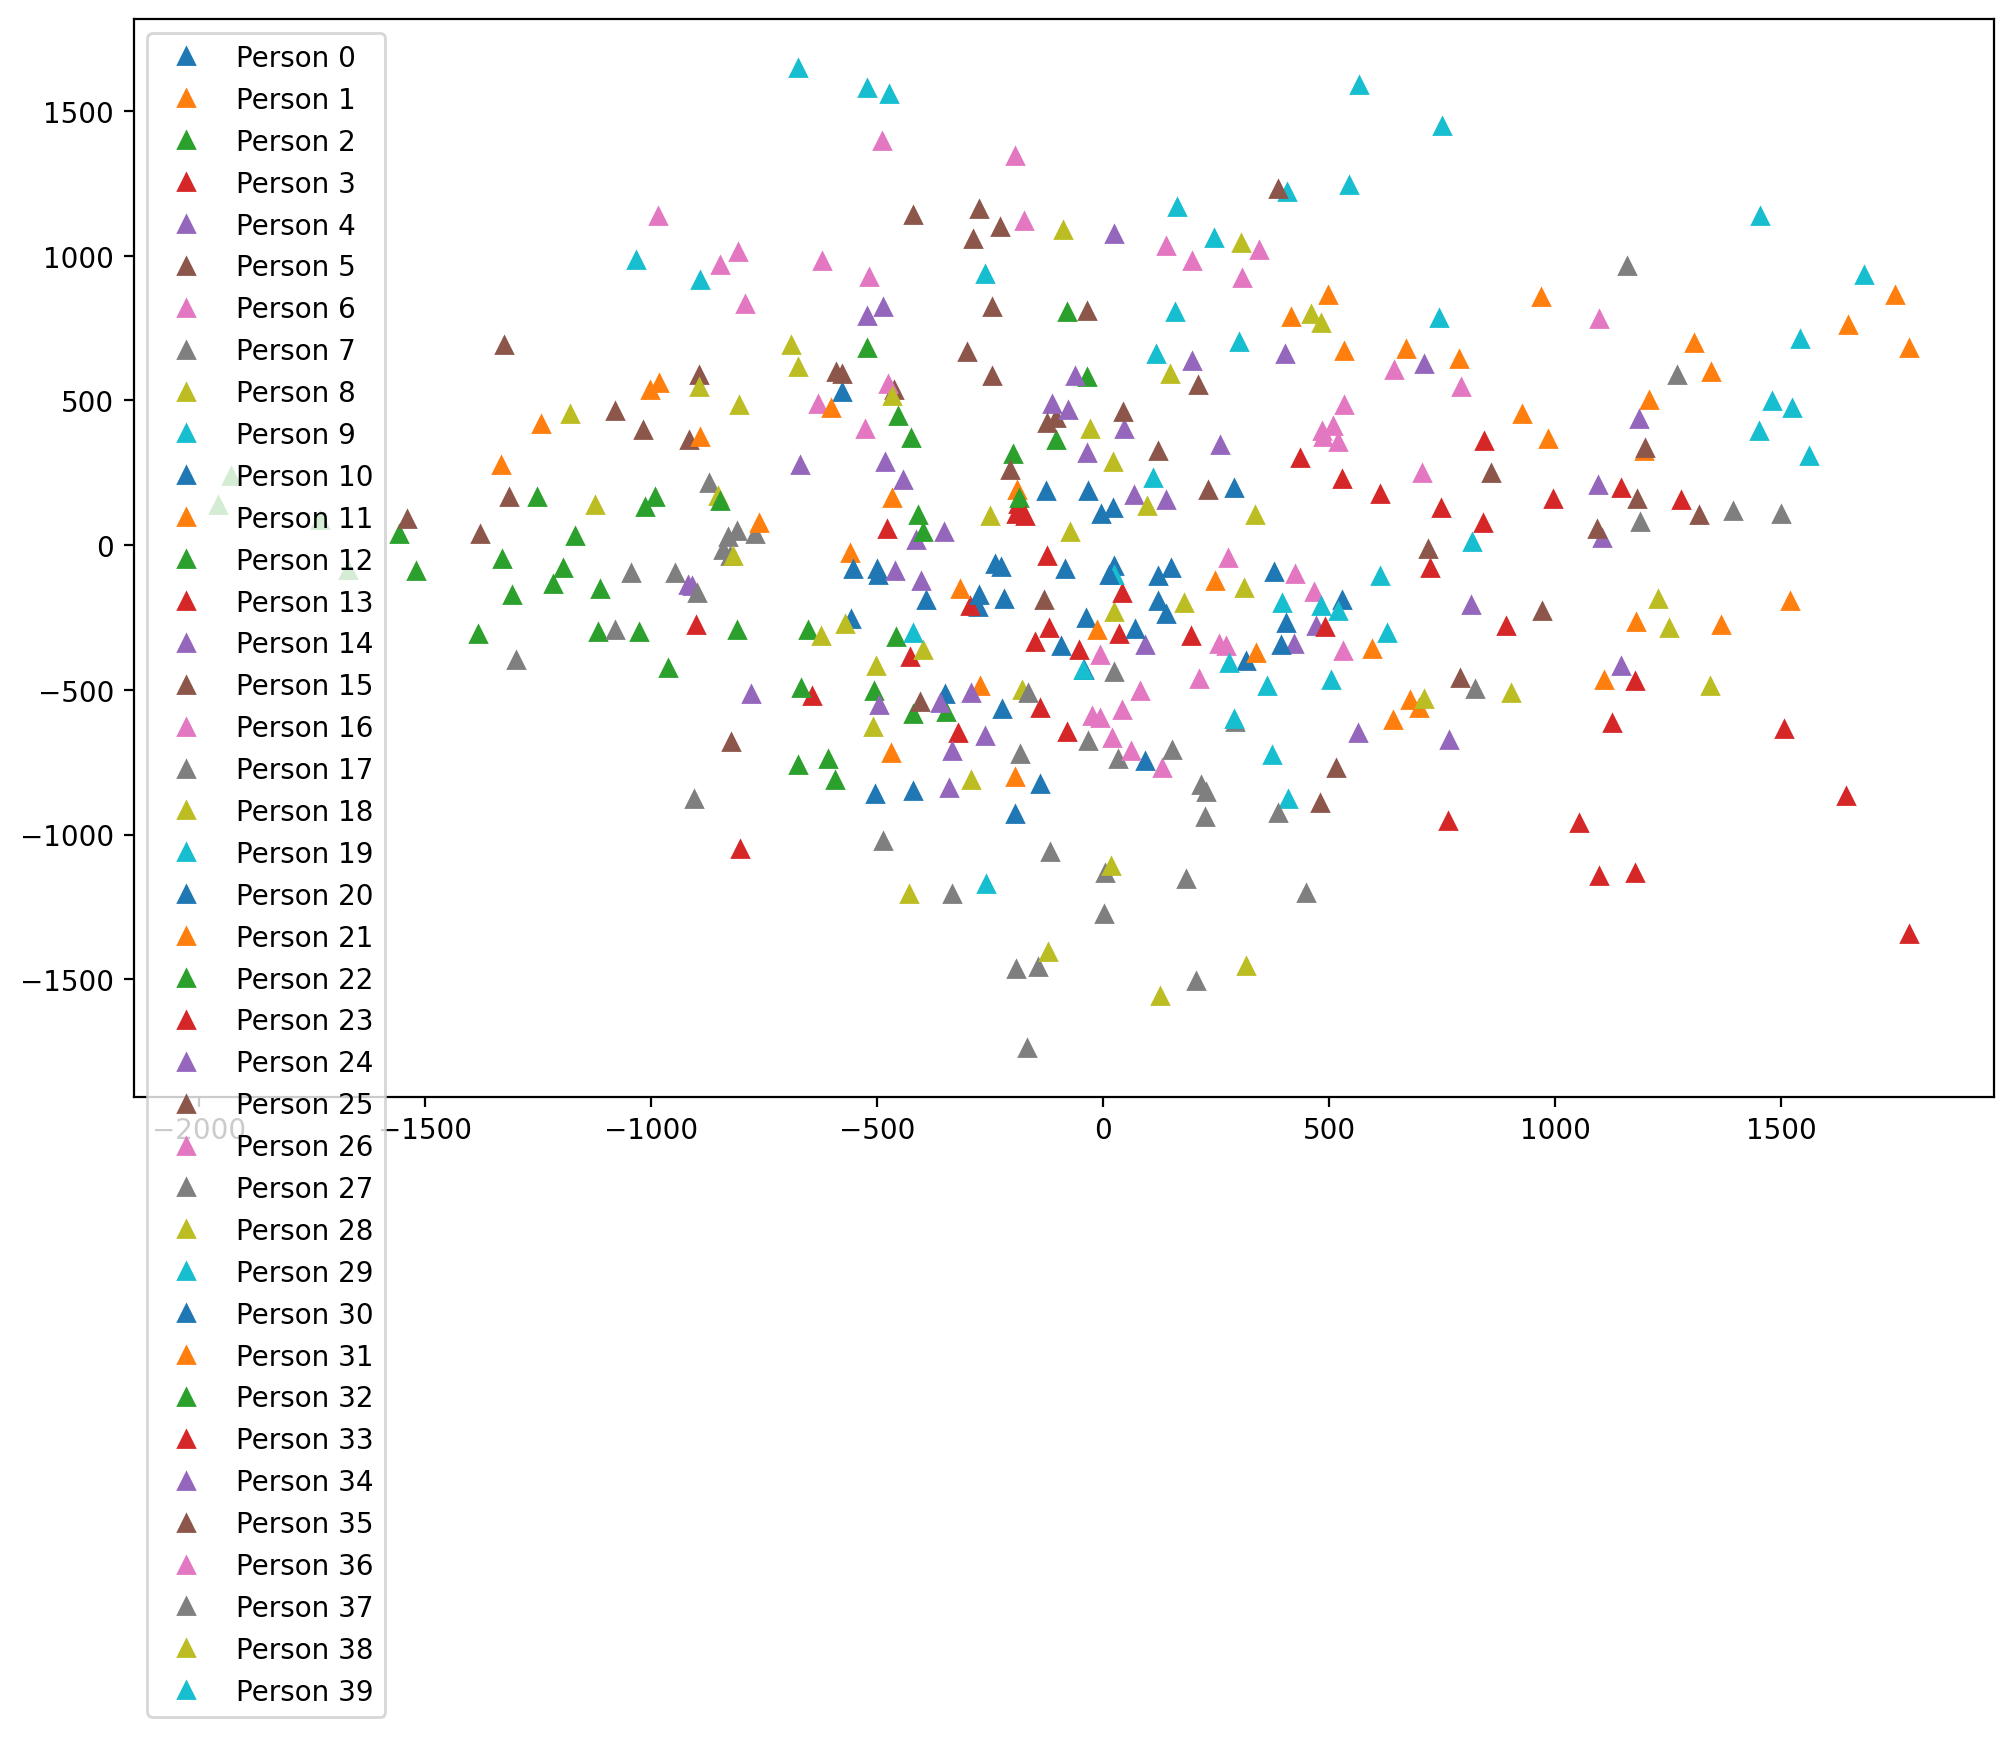

In [13]:
import itertools
import matplotlib.colors as mplcolors

# --- For all faces ---
color_cycle = itertools.cycle(mplcolors.TABLEAU_COLORS)

Person_n = []
PCAmodes_n = [6,7]
PCACoords_Pn = []

for n in range(40):
    Person_n.append(images[n*10:n*10+10] - np.tile(mean_face,(10,1)))
    #PCAmodes_n.append(n)
    PCACoords_Pn.append(pca.components_.T[:,PCAmodes - np.ones_like(PCAmodes)].T@Person_n[n].T)

for n, color in zip(range(40),color_cycle):
    plt.plot(PCACoords_Pn[n][0,:],PCACoords_Pn[n][1,:],'^',color=color,label=f'Person {n}')

plt.legend()
plt.show()

# Face Matching



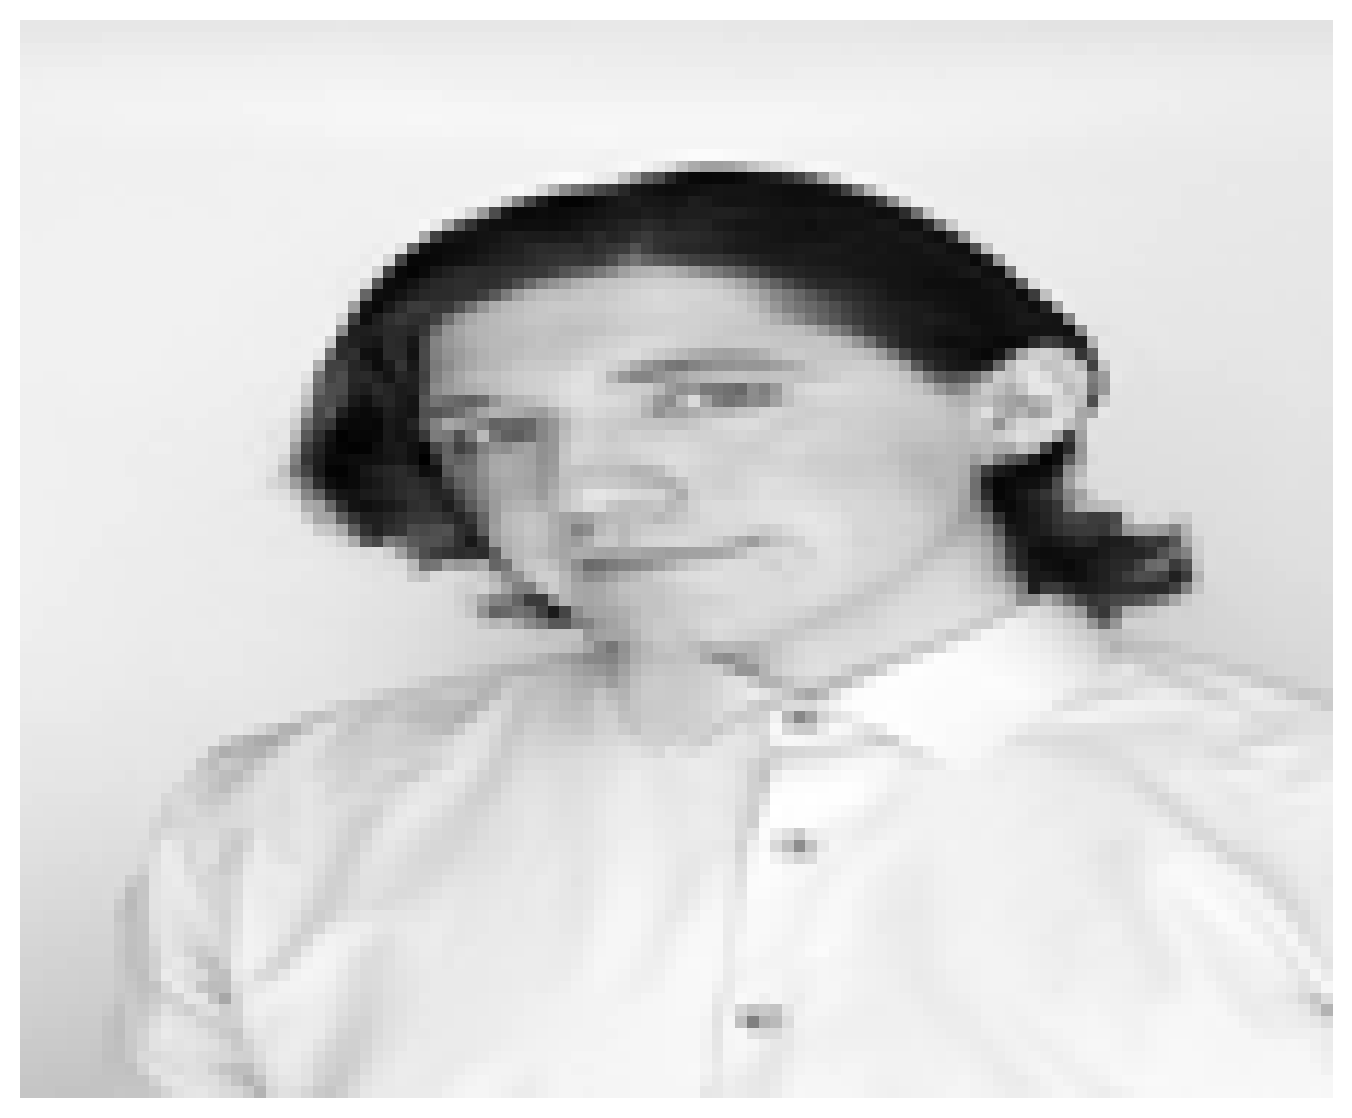

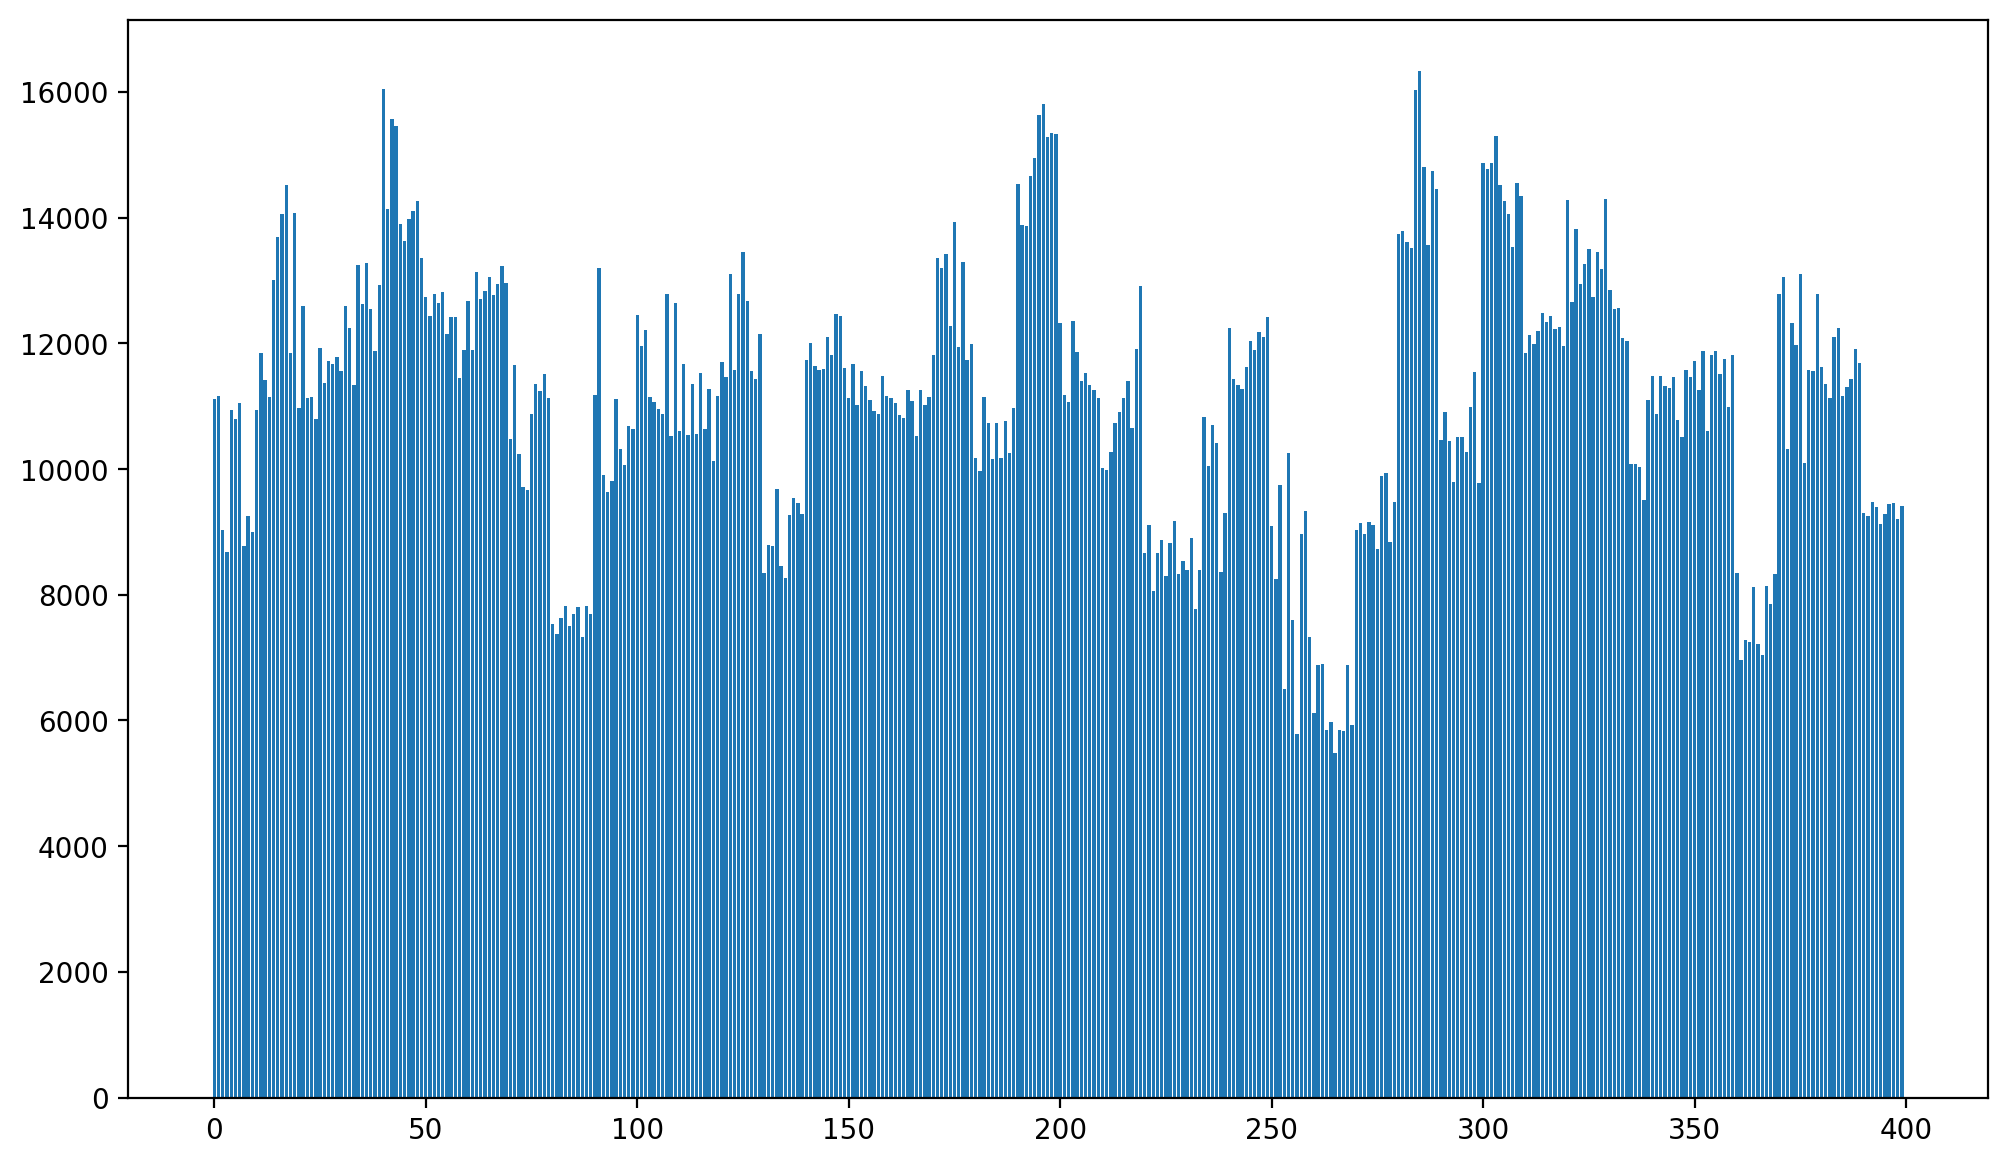

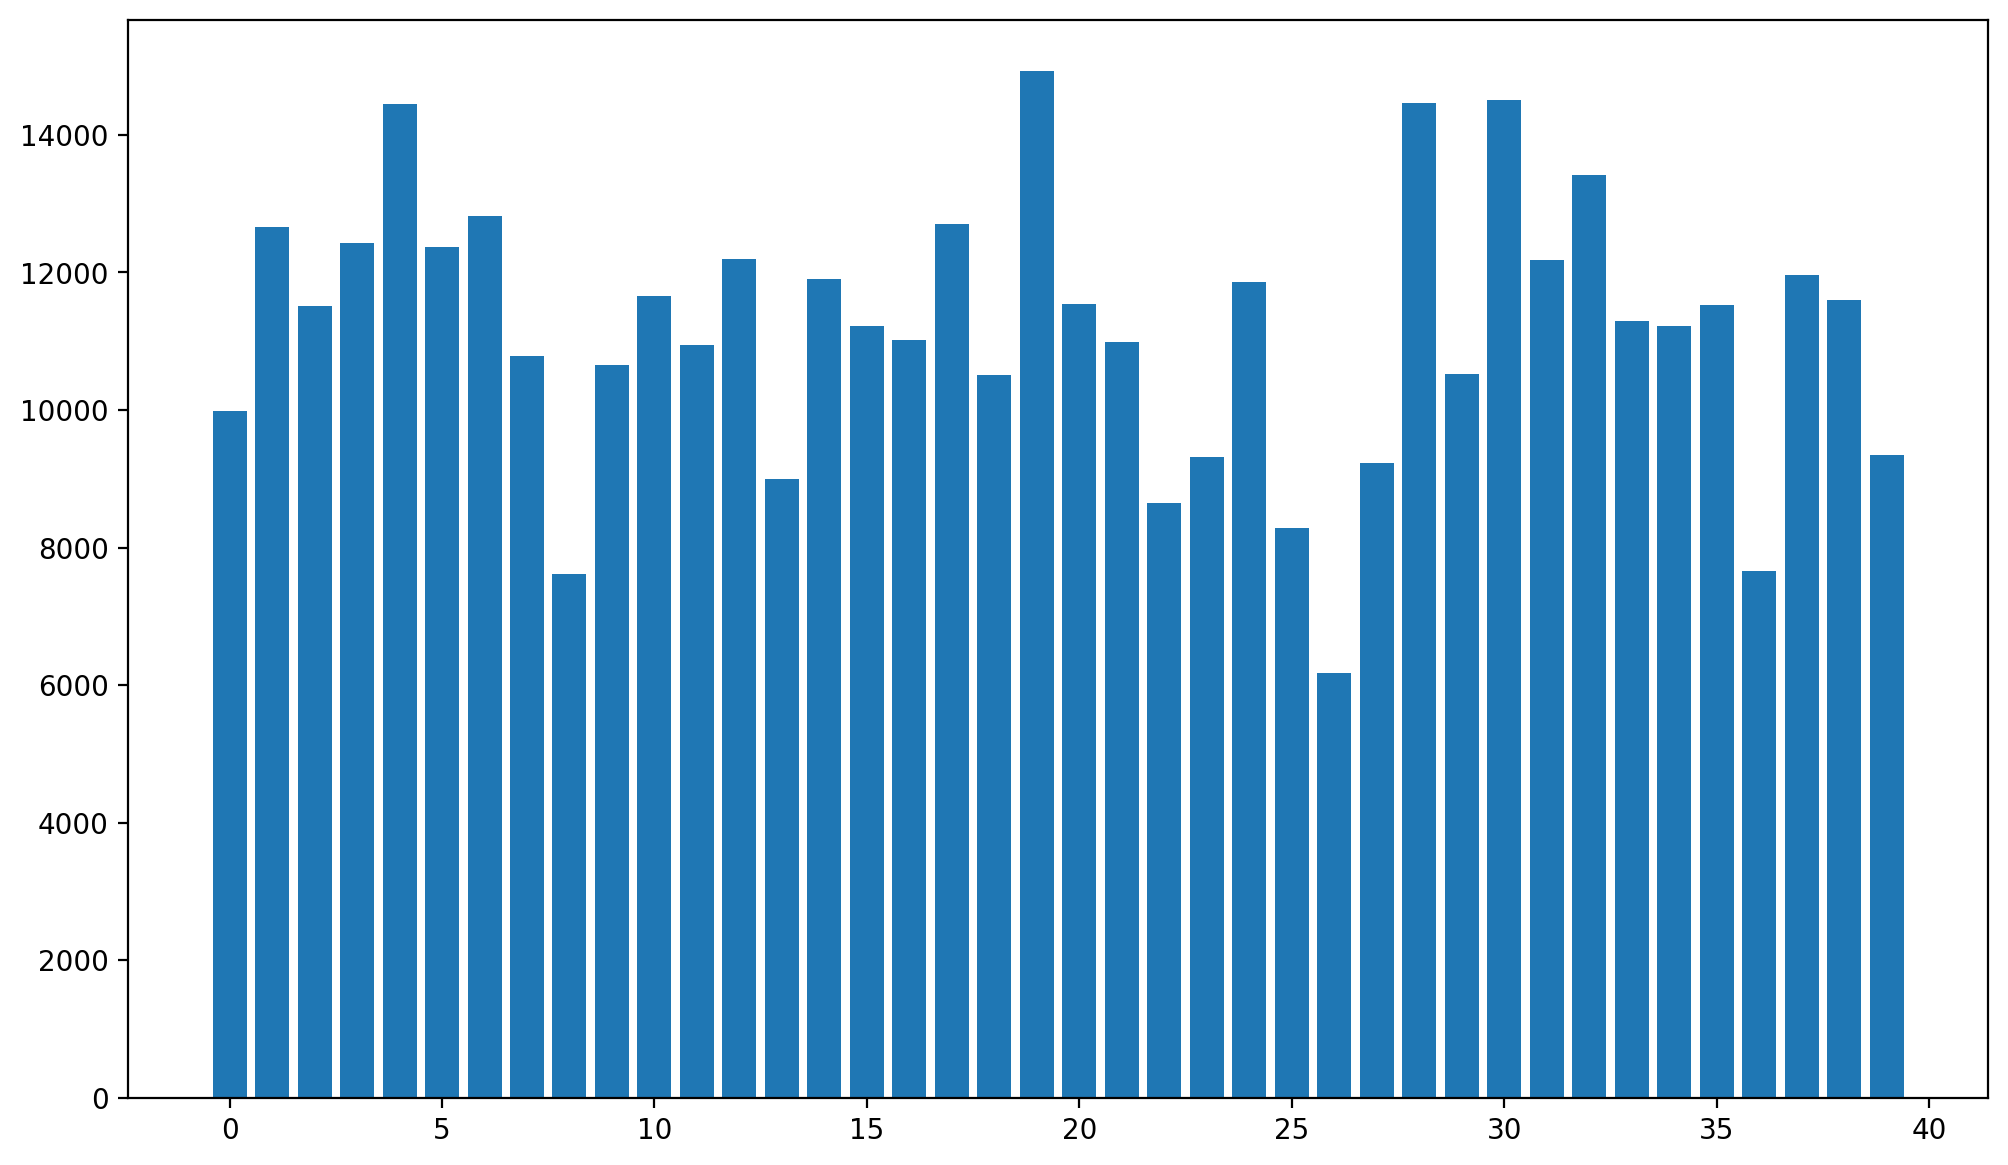

Best match is person s7


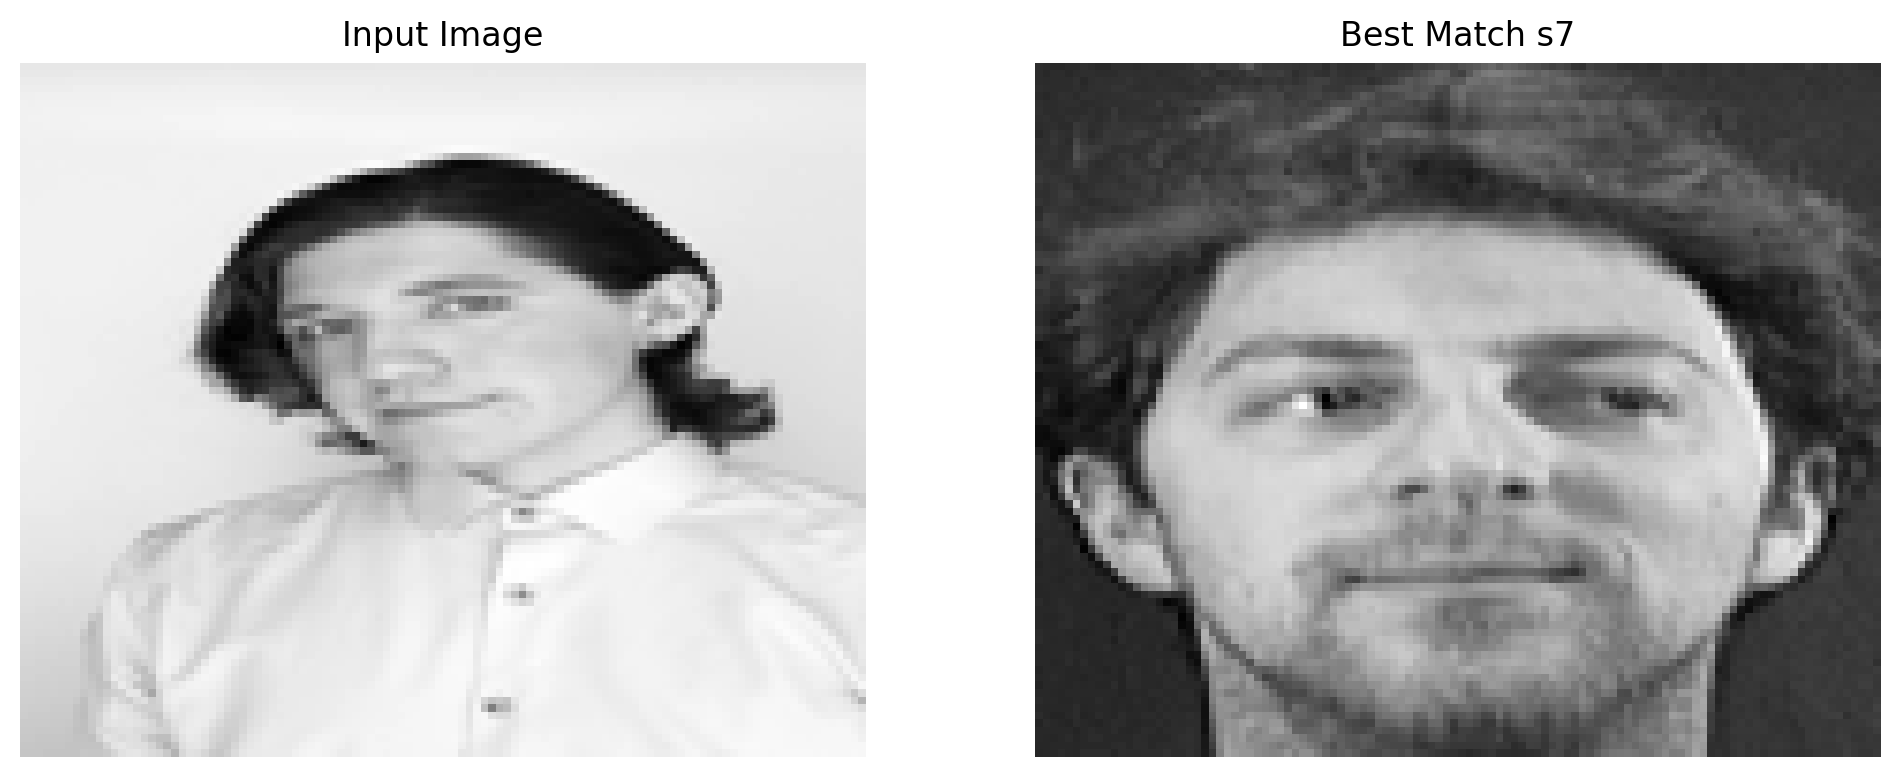

In [15]:
plt.imshow(test_images[1].reshape(IMAGE_SIZE[1], IMAGE_SIZE[0]), cmap='gray')
plt.axis('off')
plt.show()
diff = []
for n in range(len(images)):
    diff.append(mean_squared_error(test_images[1],images[n]))
people_diff = []
for n in range(40):
    people_diff.append(np.average(diff[n*10:n*10+10]))
plt.bar(range(400),diff),plt.show()
plt.bar(range(40),people_diff),plt.show()

matching = people_diff.index(min(people_diff))

print(f'Best match is person {labels[matching]}')

fig, axes = plt.subplots(1, 2)

axes[0].imshow(test_images[1].reshape(IMAGE_SIZE[1], IMAGE_SIZE[0]), cmap='gray')
axes[1].imshow(images[matching].reshape(IMAGE_SIZE[1], IMAGE_SIZE[0]), cmap='gray')

axes[0].set_title(f"Input Image")
axes[1].set_title(f"Best Match {labels[matching]}")


for i in range(2):
    axes[i].axis('off')

plt.show()
